#### Phase 9b: Robustness of the Risk Overlay and a Persistence Filter

**Project:** Regime-Aware Adaptive Trading & Risk Management System (DS605)
**Inputs (read only):** `regimes.csv`, `features.csv`, `clean.csv`, `macro.csv`, `backtest_config.json`, `backtest_metrics.csv`
**Outputs:** `data/processed/robust_*.csv`, `robust_config.json`, figures `reports/figures/robust_*.png`

---

#### 1. Why this notebook exists, and what was fixed before looking

Phase 9 ended with a mixed result: the regime overlay S1 cut the maximum drawdown a lot but did **not** raise the Sharpe ratio, and most of the benefit seemed to come from one event (the 2020 crash), while in 2022 S1 lost to buy-and-hold because the Stressed-Decline label flickers. Two questions follow, and both are answered here with rules fixed in advance:

**Part A - Is the benefit just 2020?** Year-by-year returns, then the test period with 2020 removed (and with 2020 and 2022 removed), with a paired block bootstrap.

**Part B - Does damping the flicker help?** A persistence filter: a regime (or exposure) change is acted on only after the new value has held for **N consecutive sessions**. The filter uses only information up to day *t*, and the exposure is still shifted by one day, so there is no look-ahead.

#### Rules fixed before any result was computed

| Item | Decision |
|---|---|
| Primary filter | **N = 2** (the Stressed-Decline median episode is 2 sessions, so N = 2 removes one-day flickers only). Chosen from the Phase 7 episode table, not tuned on returns |
| Sensitivity only | N = 1 (no filter) and N = 3 are reported for transparency. They are **not** used to pick N |
| Success criterion for the filter (test, 10 bps) | (a) position changes fall by **at least 30%** versus unfiltered S1, **and** (b) Sharpe **at least** as high as unfiltered S1, **and** (c) maximum drawdown still at least **25%** smaller than buy-and-hold |
| Costs, risk-free, timing, VaR, bootstrap | Exactly as in Phase 9 (10 bps headline, repo-rate risk-free, `shift(1)`, 2,000 draws, 21-session circular blocks, seed 42) |
| Rival | The VIX rule from Phase 9 (cut-offs from the training period, saved in `backtest_config.json`) is filtered in the same way, so the comparison stays fair |

#### An honest limit

The 2018-2026 test period was already used once in Phase 9. Nothing here is tuned on it (N = 2 is fixed in advance and the other values are only shown), but the test period is no longer a fresh, untouched sample. These results should be read as **robustness checks**, not as a second independent confirmation. A truly fresh check needs data that did not exist yet (live paper-trading in Phase 10) or the walk-forward regimes planned next.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40)

SEED, TD = 42, 252
TRAIN_END = pd.Timestamp("2017-12-31")
COST = 10
N_BOOT, BLOCK = 2000, 21
FILTER_N = 2
SENSITIVITY_N = (1, 2, 3)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG_DIR = ROOT / "data" / "processed", ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"robust_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

regimes  = pd.read_csv(PROC / "regimes.csv",  index_col="Date", parse_dates=True)
features = pd.read_csv(PROC / "features.csv", index_col="Date", parse_dates=True)
clean    = pd.read_csv(PROC / "clean.csv",    index_col="Date", parse_dates=True)
with open(PROC / "regime_meta.json") as f: meta = json.load(f)
with open(PROC / "backtest_config.json") as f: bcfg = json.load(f)
REGIME_NAMES = {int(k): v for k, v in meta["regime_names"].items()}
CALM, DECLINE, REBOUND = 0, 1, 2

bt = pd.DataFrame(index=regimes.index)
bt["regime"] = regimes["regime"]
bt["ret"] = clean["nifty50"].pct_change().reindex(bt.index)
bt["rf"] = regimes["risk_free_daily"]
bt["vix"] = regimes["vix_level"]
assert bt.notna().all().all() and bt.index.is_unique and bt.index.is_monotonic_increasing
START = bt.index[1]
TEST = bt.index > TRAIN_END
TRAIN = (bt.index <= TRAIN_END) & (bt.index >= START)

S1_MAP = {CALM: 1.0, REBOUND: 0.5, DECLINE: 0.0}
vix_cash, (vix_half, _) = bcfg["vix_cut_offs"]["cash_above"], bcfg["vix_cut_offs"]["half_between"]
sig = {"S0 Buy-and-hold": pd.Series(1.0, index=bt.index),
       "S1 Regime 100/50/0": bt["regime"].map(S1_MAP),
       "A VIX rule 100/50/0": pd.Series(np.where(bt["vix"] > vix_cash, 0.0, np.where(bt["vix"] > vix_half, 0.5, 1.0)), index=bt.index)}

def run_backtest(signal, cost_bps=COST, delay=1):
    e = signal.shift(delay)
    e_prev = e.shift(1).fillna(e)
    net = e * bt["ret"] + (1 - e) * bt["rf"] - cost_bps / 1e4 * (e - e_prev).abs()
    return net, e

def metrics(net, e, rf):
    ok = net.dropna().index; net, e, rf = net.loc[ok], e.loc[ok], rf.loc[ok]
    years = len(net) / TD
    wealth = (1 + net).cumprod(); peak = np.maximum.accumulate(np.r_[1.0, wealth.to_numpy()])[1:]
    mdd = float((wealth.to_numpy() / peak - 1).min()); ex = net - rf
    cagr = float(wealth.iloc[-1] ** (1 / years) - 1); de = e.diff().abs().fillna(0)
    return {"CAGR %": cagr * 100, "Volatility % (ann.)": net.std() * np.sqrt(TD) * 100, "Sharpe": ex.mean() / ex.std() * np.sqrt(TD),
            "Max drawdown %": mdd * 100, "Calmar": cagr / abs(mdd), "Position changes": int((de > 1e-9).sum()),
            "Turnover (x per year)": de.sum() / years, "Average exposure": float(e.mean())}

# ---- reproduce Phase 9 exactly before building on it ----
saved = pd.read_csv(PROC / "backtest_metrics.csv", index_col=[0, 1, 2])
tkey = "Test 2018-2026 (out of sample)"
for s in sig:
    n_, e_ = run_backtest(sig[s])
    m = metrics(n_[TEST], e_[TEST], bt["rf"])
    ref = saved.loc[(tkey, COST, s)]
    assert abs(m["Sharpe"] - ref["Sharpe"]) < 1e-4 and abs(m["Max drawdown %"] - ref["Max drawdown %"]) < 1e-3, s
print("Phase 9 results reproduced exactly (Sharpe and max drawdown of S0, S1 and the VIX rule on the test period, 10 bps).")
print("Backtest starts", START.date(), "| training sessions:", int(TRAIN.sum()), "| test sessions:", int(TEST.sum()))

Phase 9 results reproduced exactly (Sharpe and max drawdown of S0, S1 and the VIX rule on the test period, 10 bps).
Backtest starts 2008-06-10 | training sessions: 2335 | test sessions: 2173


#### 2. Part A - Is the benefit just the 2020 crash?

First the calendar-year picture (net of 10 bps), then the test period with the 2020 sessions removed.

In [2]:
net = {s: run_backtest(sig[s])[0] for s in sig}
exp = {s: run_backtest(sig[s])[1] for s in sig}
short = {"S0 Buy-and-hold": "S0", "S1 Regime 100/50/0": "S1", "A VIX rule 100/50/0": "A"}

def year_stats(r):
    r = r.dropna(); out = {}
    for y, g in r.groupby(r.index.year):
        w = (1 + g).cumprod(); pk = np.maximum.accumulate(np.r_[1.0, w.to_numpy()])[1:]
        out[y] = (float(w.iloc[-1] - 1) * 100, float((w.to_numpy() / pk - 1).min()) * 100)
    return pd.DataFrame(out, index=["return %", "worst drawdown in year %"]).T

yr = {short[s]: year_stats(net[s]) for s in sig}
yearly = pd.concat({k: v for k, v in yr.items()}, axis=1)
yearly[("S1 minus S0", "return %")] = yearly[("S1", "return %")] - yearly[("S0", "return %")]
yearly[("A minus S0", "return %")] = yearly[("A", "return %")] - yearly[("S0", "return %")]
yearly.index.name = "year"
print("CALENDAR-YEAR RESULTS, NET OF 10 bps (2008 and 2026 are partial years)")
display(yearly.round(1))
best_gain = yearly[("S1 minus S0", "return %")].sort_values(ascending=False)
print("\nS1 minus S0, years sorted (percentage points of return):")
print(best_gain.round(1).to_string())
n_win = int((yearly[("S1 minus S0", "return %")] > 0).sum()); n_yrs = len(yearly)
print(f"\nS1 beat buy-and-hold in {n_win} of {n_yrs} calendar years; "
      f"without 2020 the average yearly difference is {yearly[('S1 minus S0', 'return %')].drop(2020).mean():+.2f} points "
      f"(with 2020: {yearly[('S1 minus S0', 'return %')].mean():+.2f}).")

CALENDAR-YEAR RESULTS, NET OF 10 bps (2008 and 2026 are partial years)


S0                                S1                                 A                          S1 minus S0 A minus S0
     return % worst drawdown in year % return % worst drawdown in year % return % worst drawdown in year %    return %   return %
year                                                                                                                             
2008    -34.3                    -45.8     -3.3                     -7.8    -16.2                    -19.3        30.9       18.1
2009     75.8                    -17.6     33.1                    -11.2     13.4                    -11.2       -42.7      -62.4
2010     17.9                    -10.7      6.4                    -13.3     14.4                    -10.7       -11.6       -3.6
2011    -24.6                    -26.2    -26.2                    -26.5    -31.0                    -31.4        -1.6       -6.4
2012     27.7                    -13.8     27.7                    -13.8     27.7                    -13.8         0.0        0.0
2013      6.8                    -14.6      1.5                    -13.0      3.5                    -14.7        -5.3       -3.3
2014     31.4                     -6.5     31.4                     -6.5     24.2                     -6.5         0.0       -7.2
2015     -4.1                    -16.0     -5.6                    -16.8     -4.1                    -16.0        -1.6        0.0
2016      3.0                    -12.3      0.5                    -14.5      3.0                    -12.3        -2.6        0.0
2017     28.6                     -4.1     28.6                     -4.1     28.6                     -4.1         0.0        0.0
2018      3.2                    -14.6      3.2                    -14.6      3.2                    -14.6         0.0        0.0
2019     12.0                    -11.4     12.0                    -11.4     12.0                    -11.4         0.0        0.0
2020     14.9                    -38.4     29.4                    -13.7     16.4                    -19.1        14.5        1.5
2021     24.1                    -10.1     24.1                    -10.1     24.1                    -10.1         0.0        0.0
2022      4.3                    -16.5     -2.2                    -21.6      2.9                    -17.6        -6.5       -1.4
2023     20.0                     -7.1     20.0                     -7.1     20.0                     -7.1         0.0        0.0
2024      8.8                    -10.9      5.1                    -10.9      8.8                    -10.9        -3.7        0.0
2025     10.5                     -8.7      6.3                     -9.2     10.5                     -8.7        -4.3        0.0
2026    -12.9                    -15.6    -15.8                    -18.4    -12.9                    -15.6        -2.9        0.0


S1 minus S0, years sorted (percentage points of return):
year
2008    30.9
2020    14.5
2018     0.0
2023     0.0
2021     0.0
2019     0.0
2017     0.0
2014     0.0
2012     0.0
2015    -1.6
2011    -1.6
2016    -2.6
2026    -2.9
2024    -3.7
2025    -4.3
2013    -5.3
2022    -6.5
2010   -11.6
2009   -42.7

S1 beat buy-and-hold in 2 of 19 calendar years; without 2020 the average yearly difference is -2.88 points (with 2020: -1.96).


TEST-PERIOD METRICS WITH EVENTS REMOVED (10 bps; the remaining sessions are joined end to end)


CAGR %  Volatility % (ann.)  Sharpe  Max drawdown %  Calmar  Position changes  Average exposure
scenario                   strategy                                                                                                 
Test, all sessions         S0          9.34                16.86    0.29          -38.44    0.24                 0              1.00
                           S1          8.67                13.82    0.27          -22.32    0.39                39              0.96
                           A           9.34                14.17    0.31          -19.15    0.49                14              0.97
Test without 2020          S0          8.63                13.93    0.26          -17.23    0.50                 0              1.00
                           S1          6.20                13.60    0.10          -22.32    0.28                24              0.99
                           A           8.44                13.91    0.25          -18.32    0.46                 2              1.00
Test without 2020 and 2022 S0          9.27                13.36    0.30          -15.77    0.59                 0              1.00
                           S1          7.51                13.15    0.18          -21.17    0.35                10              0.99
                           A           9.27                13.36    0.30          -15.77    0.59                 0              1.00

PAIRED BLOCK BOOTSTRAP ON THE SAME SESSIONS


Sharpe difference   Sharpe 95% CI  CI excludes 0  Max-drawdown reduction % (point) Max-drawdown reduction % 95% CI
scenario                   comparison                                                                                                                     
Test, all sessions         S1 minus S0              -0.02  [-0.34, +0.38]          False                             41.94                       [-25, 60]
                           A minus S0                0.02  [-0.24, +0.29]          False                             50.19                       [-10, 50]
Test without 2020          S1 minus S0              -0.16  [-0.31, -0.04]           True                            -29.54                        [-39, 3]
                           A minus S0               -0.01  [-0.04, +0.00]          False                             -6.35                         [-7, 0]
Test without 2020 and 2022 S1 minus S0              -0.12  [-0.26, +0.00]          False                            -34.26                        [-28, 0]
                           A minus S0                0.00  [+0.00, +0.00]          False                              0.00                          [0, 0]

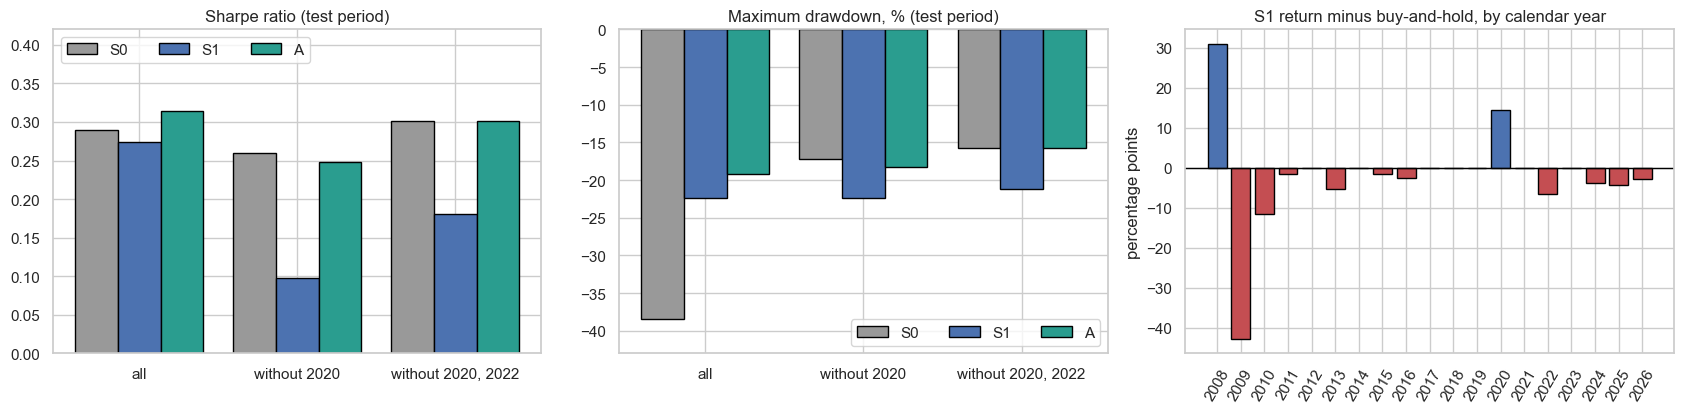

In [3]:
def circular_blocks(n, rng, block=BLOCK):
    nb = int(np.ceil(n / block))
    return ((rng.integers(0, n, nb)[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]

def boot_pair(ra, rb, rf, seed=SEED):
    # paired circular block bootstrap of (Sharpe a - Sharpe b) and of the max-drawdown reduction of a versus b
    ra, rb, rf = np.asarray(ra), np.asarray(rb), np.asarray(rf); n = len(ra)
    rng = np.random.default_rng(seed); ds = np.empty(N_BOOT); dd = np.empty(N_BOOT)
    def mdd(x):
        w = np.cumprod(1 + x); pk = np.maximum.accumulate(np.r_[1.0, w])[1:]; return (w / pk - 1).min()
    for b in range(N_BOOT):
        i = circular_blocks(n, rng)
        xa, xb, f = ra[i], rb[i], rf[i]
        ds[b] = (xa - f).mean() / (xa - f).std(ddof=1) * np.sqrt(TD) - (xb - f).mean() / (xb - f).std(ddof=1) * np.sqrt(TD)
        dd[b] = (1 - mdd(xa) / mdd(xb)) * 100
    return {"sharpe_lo": float(np.percentile(ds, 2.5)), "sharpe_hi": float(np.percentile(ds, 97.5)),
            "dd_red_lo": float(np.percentile(dd, 2.5)), "dd_red_hi": float(np.percentile(dd, 97.5))}

yrs = bt.index.year
scen = {"Test, all sessions": TEST, "Test without 2020": TEST & (yrs != 2020), "Test without 2020 and 2022": TEST & (yrs != 2020) & (yrs != 2022)}
rows, brows = {}, {}
for sname, mask in scen.items():
    for s in sig:
        rows[(sname, short[s])] = metrics(net[s][mask], exp[s][mask], bt["rf"])
    for a in ("S1", "A"):
        sa = [k for k, v in short.items() if v == a][0]
        r = boot_pair(net[sa][mask], net["S0 Buy-and-hold"][mask], bt.loc[mask, "rf"])
        brows[(sname, f"{a} minus S0")] = {"Sharpe difference": rows[(sname, a)]["Sharpe"] - rows[(sname, "S0")]["Sharpe"],
            "Sharpe 95% CI": f"[{r['sharpe_lo']:+.2f}, {r['sharpe_hi']:+.2f}]", "CI excludes 0": bool(r['sharpe_lo'] > 0 or r['sharpe_hi'] < 0),
            "Max-drawdown reduction % (point)": (1 - rows[(sname, a)]["Max drawdown %"] / rows[(sname, "S0")]["Max drawdown %"]) * 100,
            "Max-drawdown reduction % 95% CI": f"[{r['dd_red_lo']:.0f}, {r['dd_red_hi']:.0f}]", **{k: v for k, v in r.items()}}
ex_metrics = pd.DataFrame.from_dict(rows, orient="index"); ex_metrics.index.names = ["scenario", "strategy"]
ex_boot = pd.DataFrame.from_dict(brows, orient="index"); ex_boot.index.names = ["scenario", "comparison"]
print("TEST-PERIOD METRICS WITH EVENTS REMOVED (10 bps; the remaining sessions are joined end to end)")
display(ex_metrics[["CAGR %", "Volatility % (ann.)", "Sharpe", "Max drawdown %", "Calmar", "Position changes", "Average exposure"]].round(2))
print("PAIRED BLOCK BOOTSTRAP ON THE SAME SESSIONS")
display(ex_boot[["Sharpe difference", "Sharpe 95% CI", "CI excludes 0", "Max-drawdown reduction % (point)", "Max-drawdown reduction % 95% CI"]].round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
cols = {"S0": "#999999", "S1": "#4c72b0", "A": "#2a9d8f"}
x_ = np.arange(len(scen))
for j, (met, ttl) in enumerate([("Sharpe", "Sharpe ratio"), ("Max drawdown %", "Maximum drawdown, %")]):
    for k, (lab, off) in enumerate([("S0", -.27), ("S1", 0), ("A", .27)]):
        ax[j].bar(x_ + off, [ex_metrics.loc[(sn, lab), met] for sn in scen], .27, color=cols[lab], edgecolor="black", label=lab)
    ax[j].set_xticks(x_); ax[j].set_xticklabels(["all", "without 2020", "without 2020, 2022"]); ax[j].set_title(ttl + " (test period)")
    if j == 0: ax[j].set_ylim(0, 0.42); ax[j].legend(ncol=3, loc="upper left")
    else: ax[j].set_ylim(-43, 0); ax[j].legend(ncol=3, loc="lower right")
d = yearly[("S1 minus S0", "return %")]
ax[2].bar(d.index.astype(str), d.values, color=np.where(d.values >= 0, "#4c72b0", "#c44e52"), edgecolor="black")
ax[2].axhline(0, color="black", lw=1); ax[2].set_ylabel("percentage points"); ax[2].set_title("S1 return minus buy-and-hold, by calendar year")
ax[2].tick_params(axis="x", rotation=60)
save_fig("leave_out_2020")

#### Interpretation of Part A (from the outputs above)

**The Phase 9 benefit is one event.** S1 beat buy-and-hold in only **2 of 19 calendar years: 2008 and 2020**. In 8 years it was identical (no stress label, so fully invested), and in the other 9 it was behind. Only 2020 is a test-period win (+14.5 points; 2008 is in the training period). The biggest single miss is **2009 (-42.7 points)**: the stressed labels kept S1 out of, or half out of, the rebound. This is the Phase 7 finding showing up in money: stress has been followed by high average returns.

**Remove 2020 and the overlay loses.** On the test period without 2020, S1 has a Sharpe of **0.10 versus 0.26** for buy-and-hold (difference -0.16, 95% interval [-0.31, -0.04], which excludes zero), and its maximum drawdown is **-22.3% versus -17.2%**, so S1 is now the *riskier* of the two. Without 2020 and 2022 the Sharpe gap is -0.12 with an interval [-0.26, 0.00] that only just touches zero. The 2022 whipsaw is the visible cause: S1 returned -2.2% against +4.3% for buy-and-hold.

**The VIX rule behaves differently.** Outside 2020 it makes only 2 position changes and is almost identical to buy-and-hold (Sharpe difference -0.01). It is cheap crash insurance that does nothing in other years, whereas S1 pays a continuing price (whipsaw) for the same protection.

**How to read this fairly.** Insurance looks bad in years without a crash, so removing the one crash is a deliberately hard test and not a verdict that the overlay is worthless. What it does show is that the evidence for S1 rests on a single episode, and that the claim "the regimes improve risk-adjusted returns" is **not** supported; "the regimes reduce the damage of a crash like 2020, at a price in other years" is. Two cautions about the diagnostic itself: joining the sessions either side of a removed year end to end creates an artificial seam, and the yearly averages printed above mix training and test years.

#### 3. Part B - A persistence filter against flicker

`hold_filter(s, n)` leaves the position unchanged until the *new* value has been seen on `n` consecutive sessions up to and including day *t*. With `n = 1` it is the original signal. The filter is applied to the exposure signal of both S1 and the VIX rule.

In [4]:
def hold_filter(s, n):
    v = s.to_numpy(); out = v.copy()
    for t in range(1, len(v)):
        if t >= n - 1 and np.all(v[t - n + 1:t + 1] == v[t]) and v[t] != out[t - 1]: out[t] = v[t]
        else: out[t] = out[t - 1]
    return pd.Series(out, index=s.index)

# causality check: the filtered value at t must not change if the future is altered
z = sig["S1 Regime 100/50/0"]; zz = z.copy(); zz.iloc[3000:] = 0.0
assert hold_filter(z, 2).iloc[:3000].equals(hold_filter(zz, 2).iloc[:3000]), "filter looks into the future"
assert hold_filter(z, 1).equals(z)
print("Filter checks passed: no look-ahead, and N = 1 reproduces the original signal.")

fsig = {"S0 Buy-and-hold": sig["S0 Buy-and-hold"]}
for base, key in [("S1 Regime 100/50/0", "S1"), ("A VIX rule 100/50/0", "A")]:
    for n in SENSITIVITY_N:
        fsig[f"{key} N={n}"] = hold_filter(sig[base], n)
fnet = {}; fexp = {}
for s, g in fsig.items(): fnet[s], fexp[s] = run_backtest(g)

def table(mask):
    return pd.DataFrame({s: metrics(fnet[s][mask], fexp[s][mask], bt["rf"]) for s in fsig}).T
ftest, ftrain = table(TEST), table(TRAIN)
print("TEST PERIOD (out of sample), 10 bps")
display(ftest[["CAGR %", "Volatility % (ann.)", "Sharpe", "Max drawdown %", "Calmar", "Position changes", "Turnover (x per year)", "Average exposure"]].round(2))
print("TRAINING PERIOD (in sample), 10 bps")
display(ftrain[["CAGR %", "Volatility % (ann.)", "Sharpe", "Max drawdown %", "Calmar", "Position changes", "Turnover (x per year)", "Average exposure"]].round(2))

# ---- pre-registered criterion for the primary filter (S1, N = 2) ----
p, base, s0 = f"S1 N={FILTER_N}", "S1 N=1", "S0 Buy-and-hold"
chg_fall = (1 - ftest.loc[p, "Position changes"] / ftest.loc[base, "Position changes"]) * 100
dd_red = (1 - ftest.loc[p, "Max drawdown %"] / ftest.loc[s0, "Max drawdown %"]) * 100
ca, cb, cc = bool(chg_fall >= 30), bool(ftest.loc[p, "Sharpe"] >= ftest.loc[base, "Sharpe"]), bool(dd_red >= 25)
print("\nPRE-REGISTERED CRITERION FOR THE PERSISTENCE FILTER (S1, N = 2, test, 10 bps)")
print(f"  (a) position changes fall by at least 30%: {int(ftest.loc[base, 'Position changes'])} -> {int(ftest.loc[p, 'Position changes'])} = {chg_fall:.0f}% fewer -> {'PASS' if ca else 'FAIL'}")
print(f"  (b) Sharpe at least that of unfiltered S1: {ftest.loc[p, 'Sharpe']:.3f} vs {ftest.loc[base, 'Sharpe']:.3f} -> {'PASS' if cb else 'FAIL'}")
print(f"  (c) max drawdown at least 25% smaller than buy-and-hold: {ftest.loc[p, 'Max drawdown %']:.1f}% vs {ftest.loc[s0, 'Max drawdown %']:.1f}% = {dd_red:.1f}% smaller -> {'PASS' if cc else 'FAIL'}")
FILTER_PASS = bool(ca and cb and cc)
print(f"  OVERALL: {'the filter WORKS under the pre-registered criterion' if FILTER_PASS else 'the filter DOES NOT meet the pre-registered criterion'}")

Filter checks passed: no look-ahead, and N = 1 reproduces the original signal.
TEST PERIOD (out of sample), 10 bps


,CAGR %,Volatility % (ann.),Sharpe,Max drawdown %,Calmar,Position changes,Turnover (x per year),Average exposure
S0 Buy-and-hold,9.34,16.86,0.29,-38.44,0.24,0.0,0.00,1.00
S1 N=1,8.67,13.82,0.27,-22.32,0.39,39.0,3.94,0.96
S1 N=2,9.41,13.96,0.32,-19.41,0.48,19.0,1.86,0.97
S1 N=3,9.81,14.01,0.35,-20.39,0.48,12.0,1.04,0.97
A N=1,9.34,14.17,0.31,-19.15,0.49,14.0,0.81,0.97
A N=2,9.93,14.18,0.35,-18.95,0.52,6.0,0.35,0.97
A N=3,8.45,14.66,0.25,-27.79,0.30,5.0,0.35,0.97


TRAINING PERIOD (in sample), 10 bps


,CAGR %,Volatility % (ann.),Sharpe,Max drawdown %,Calmar,Position changes,Turnover (x per year),Average exposure
S0 Buy-and-hold,9.61,21.93,0.21,-45.75,0.21,0.0,0.00,1.00
S1 N=1,8.31,15.21,0.15,-28.17,0.30,68.0,6.26,0.87
S1 N=2,8.42,15.14,0.15,-31.01,0.27,38.0,3.35,0.87
S1 N=3,7.58,15.09,0.10,-31.15,0.24,32.0,2.81,0.87
A N=1,4.95,14.90,-0.06,-32.92,0.15,80.0,4.48,0.87
A N=2,5.76,14.92,-0.01,-30.32,0.19,39.0,2.10,0.87
A N=3,6.60,14.96,0.04,-28.59,0.23,23.0,1.24,0.87



PRE-REGISTERED CRITERION FOR THE PERSISTENCE FILTER (S1, N = 2, test, 10 bps)
  (a) position changes fall by at least 30%: 39 -> 19 = 51% fewer -> PASS
  (b) Sharpe at least that of unfiltered S1: 0.322 vs 0.275 -> PASS
  (c) max drawdown at least 25% smaller than buy-and-hold: -19.4% vs -38.4% = 49.5% smaller -> PASS
  OVERALL: the filter WORKS under the pre-registered criterion


PAIRED BLOCK BOOTSTRAP, test period, 10 bps (2000 draws, block 21, seed 42)


,Sharpe difference,Sharpe 95% CI,CI excludes 0,Max-drawdown reduction % (point),Max-drawdown reduction % 95% CI
S1 N=2 minus S0 Buy-and-hold,0.03,"[-0.26, +0.35]",False,49.52,"[-16, 55]"
S1 N=2 minus S1 N=1,0.05,"[-0.11, +0.19]",False,13.05,"[-29, 20]"
S1 N=3 minus S1 N=1,0.07,"[-0.07, +0.21]",False,8.66,"[-22, 21]"
A N=2 minus S0 Buy-and-hold,0.06,"[-0.20, +0.35]",False,50.71,"[-8, 53]"
A N=2 minus A N=1,0.04,"[-0.01, +0.10]",False,1.04,"[-4, 11]"
S1 N=2 minus A N=2,-0.03,"[-0.15, +0.07]",False,-2.42,"[-18, 13]"


RETURNS IN SELECTED WINDOWS, % (net of 10 bps)


,S0 Buy-and-hold,S1 N=1,S1 N=2,S1 N=3,A N=1,A N=2
Covid crash 2020-02-01 to 2020-04-30,-17.6,-6.3,-10.8,-10.8,-13.7,-12.9
Calendar 2020,14.9,29.4,23.8,26.4,16.4,20.3
Calendar 2022,4.3,-2.2,2.0,0.4,2.9,4.3
Calendar 2023,20.0,20.0,20.0,20.0,20.0,20.0
Calendar 2025,10.5,6.3,10.5,10.5,10.5,10.5


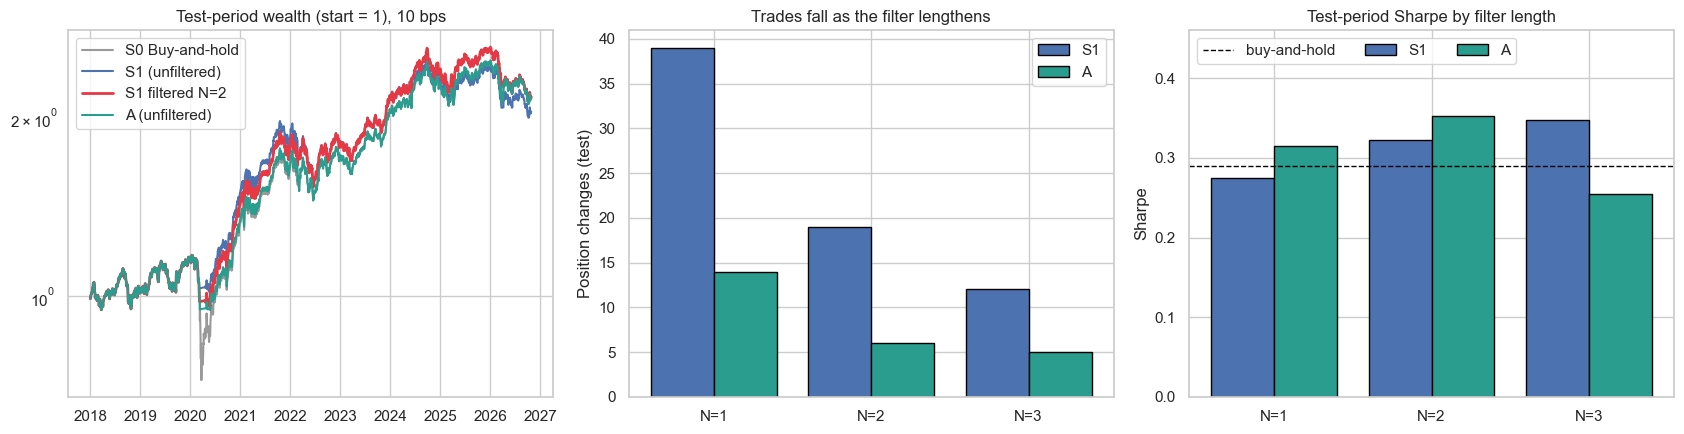

In [5]:
# bootstrap on the full test period: filtered S1 vs buy-and-hold, vs unfiltered S1, and the filtered VIX rule vs buy-and-hold
rf_te = bt.loc[TEST, "rf"]
pairs_f = [("S1 N=2", "S0 Buy-and-hold"), ("S1 N=2", "S1 N=1"), ("S1 N=3", "S1 N=1"), ("A N=2", "S0 Buy-and-hold"), ("A N=2", "A N=1"), ("S1 N=2", "A N=2")]
brows = {}
for a, b in pairs_f:
    r = boot_pair(fnet[a][TEST], fnet[b][TEST], rf_te)
    brows[f"{a}  minus  {b}"] = {"Sharpe difference": ftest.loc[a, "Sharpe"] - ftest.loc[b, "Sharpe"], "Sharpe 95% CI": f"[{r['sharpe_lo']:+.2f}, {r['sharpe_hi']:+.2f}]",
        "CI excludes 0": bool(r['sharpe_lo'] > 0 or r['sharpe_hi'] < 0), "Max-drawdown reduction % (point)": (1 - ftest.loc[a, "Max drawdown %"] / ftest.loc[b, "Max drawdown %"]) * 100,
        "Max-drawdown reduction % 95% CI": f"[{r['dd_red_lo']:.0f}, {r['dd_red_hi']:.0f}]"}
fboot = pd.DataFrame.from_dict(brows, orient="index")
print(f"PAIRED BLOCK BOOTSTRAP, test period, 10 bps ({N_BOOT} draws, block {BLOCK}, seed {SEED})")
display(fboot.round(2))

# calendar-window view: where does the filter help or hurt?
def window_ret(s, a, b):
    r = fnet[s].loc[a:b].dropna(); return float((1 + r).prod() - 1) * 100
wins = {"Covid crash 2020-02-01 to 2020-04-30": ("2020-02-01", "2020-04-30"), "Calendar 2020": ("2020-01-01", "2020-12-31"), "Calendar 2022": ("2022-01-01", "2022-12-31"),
        "Calendar 2023": ("2023-01-01", "2023-12-31"), "Calendar 2025": ("2025-01-01", "2025-12-31")}
wtab = pd.DataFrame({w: {s: window_ret(s, *rng) for s in ["S0 Buy-and-hold", "S1 N=1", "S1 N=2", "S1 N=3", "A N=1", "A N=2"]} for w, rng in wins.items()}).T
print("RETURNS IN SELECTED WINDOWS, % (net of 10 bps)")
display(wtab.round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for s, c, lw in [("S0 Buy-and-hold", "#999999", 1.5), ("S1 N=1", "#4c72b0", 1.5), ("S1 N=2", "#e63946", 2), ("A N=1", "#2a9d8f", 1.5)]:
    ax[0].plot((1 + fnet[s][TEST]).cumprod(), color=c, lw=lw, label=s.replace("N=1", "(unfiltered)").replace("S1 N=2", "S1 filtered N=2"))
ax[0].set_yscale("log"); ax[0].set_title("Test-period wealth (start = 1), 10 bps"); ax[0].legend()
xs = np.arange(3)
for off, key, c in [(-.2, "S1", "#4c72b0"), (.2, "A", "#2a9d8f")]:
    ax[1].bar(xs + off, [ftest.loc[f"{key} N={n}", "Position changes"] for n in SENSITIVITY_N], .4, color=c, edgecolor="black", label=key)
ax[1].set_xticks(xs); ax[1].set_xticklabels([f"N={n}" for n in SENSITIVITY_N]); ax[1].set_ylabel("Position changes (test)"); ax[1].set_title("Trades fall as the filter lengthens"); ax[1].legend()
for off, key, c in [(-.2, "S1", "#4c72b0"), (.2, "A", "#2a9d8f")]:
    ax[2].bar(xs + off, [ftest.loc[f"{key} N={n}", "Sharpe"] for n in SENSITIVITY_N], .4, color=c, edgecolor="black", label=key)
ax[2].axhline(ftest.loc["S0 Buy-and-hold", "Sharpe"], color="black", ls="--", lw=1, label="buy-and-hold")
ax[2].set_xticks(xs); ax[2].set_xticklabels([f"N={n}" for n in SENSITIVITY_N]); ax[2].set_ylabel("Sharpe"); ax[2].set_ylim(0, 0.46); ax[2].set_title("Test-period Sharpe by filter length"); ax[2].legend(ncol=3, loc="upper left")
save_fig("signal_filter")

#### Interpretation of Part B (from the outputs above)

**The pre-registered criterion is met.** With N = 2, S1's position changes fall from 39 to 19 (51% fewer, criterion 30%), the test Sharpe rises from 0.275 to **0.322** (criterion: at least the unfiltered value), and the maximum drawdown is -19.4% against -38.4% for buy-and-hold (49.5% smaller, criterion 25%). N = 2 was fixed from the Phase 7 episode table before any of this was computed, so this is not a result of searching over N.

**Where the gain comes from.** The filter removes the one-day flickers, so the 2022 loss disappears (S1: -2.2%, filtered: +2.0%) and 2025 is restored to buy-and-hold's +10.5%. Turnover halves (3.94 to 1.86 per year), which at 10 bps is worth about 0.2 points of return a year; the CAGR gain is larger (8.67% to 9.41%), so most of it is avoided whipsaw and not just saved costs. **The price is slower protection**: in the Covid window the filtered S1 lost 10.8% against 6.3% unfiltered (buy-and-hold: 17.6%).

**But the evidence is weak, and three facts argue for caution.**
1. *No difference is statistically distinguishable.* Filtered S1 minus unfiltered S1: Sharpe +0.05, interval [-0.11, +0.19]. Filtered S1 minus buy-and-hold: +0.03, interval [-0.26, +0.35].
2. *The gain does not repeat in the training period.* In sample, S1 N = 2 has the same Sharpe as unfiltered S1 (0.15 and 0.15) and a *deeper* drawdown (-31.0% against -28.2%).
3. *The results are not smooth in N.* For the VIX rule, N = 2 gives a Sharpe of 0.35 but N = 3 gives 0.25 with a drawdown of -27.8% (one extra day of delay missed a sharp fall). A rule whose quality swings that much with one day of delay is fragile. For S1, N = 3 is nominally the best (0.35), but N was not allowed to be selected from the test period.

**Verdict for Part B:** the persistence filter is a sensible, low-cost improvement that cuts trading by half and passed its rule, but on this evidence it is a **modest, statistically unproven** gain and not a fix. It also leaves the central result of Part A untouched.

#### 4. Part C - Experiment log, saved outputs and checks

Every experiment is logged with its pre-registered rule and its verdict, so nobody can later say the answer was chosen after the fact.

In [6]:
s1m, s0m = ftest.loc["S1 N=1"], ftest.loc["S0 Buy-and-hold"]
log = pd.DataFrame([
    {"id": "E1", "experiment": "Phase 9 baseline: S1 vs buy-and-hold", "rule fixed in advance": "drawdown >= 25% smaller; Sharpe-difference CI not entirely below 0",
     "result": f"drawdown {(1 - s1m['Max drawdown %'] / s0m['Max drawdown %']) * 100:.0f}% smaller; Sharpe {s1m['Sharpe']:.2f} vs {s0m['Sharpe']:.2f}", "verdict": "PASS (criterion met), but no Sharpe gain"},
    {"id": "E2", "experiment": "Test period without 2020 (and without 2020 and 2022)", "rule fixed in advance": "diagnostic, no pass/fail",
     "result": f"S1 Sharpe {ex_metrics.loc[('Test without 2020', 'S1'), 'Sharpe']:.2f} vs S0 {ex_metrics.loc[('Test without 2020', 'S0'), 'Sharpe']:.2f}; drawdown reduction {(1 - ex_metrics.loc[('Test without 2020', 'S1'), 'Max drawdown %'] / ex_metrics.loc[('Test without 2020', 'S0'), 'Max drawdown %']) * 100:.0f}%", "verdict": "see interpretation"},
    {"id": "E3", "experiment": "Persistence filter N=2 on S1", "rule fixed in advance": "changes -30% or more; Sharpe >= unfiltered S1; drawdown >= 25% smaller than S0",
     "result": f"changes {int(ftest.loc['S1 N=1', 'Position changes'])} -> {int(ftest.loc['S1 N=2', 'Position changes'])}; Sharpe {ftest.loc['S1 N=2', 'Sharpe']:.3f} vs {ftest.loc['S1 N=1', 'Sharpe']:.3f}; drawdown {ftest.loc['S1 N=2', 'Max drawdown %']:.1f}%",
     "verdict": "PASS" if FILTER_PASS else "FAIL"},
    {"id": "E4", "experiment": "Sensitivity N=3 and filtered VIX rule", "rule fixed in advance": "reported only, never used to pick N",
     "result": f"S1 N=3 Sharpe {ftest.loc['S1 N=3', 'Sharpe']:.3f}; A N=2 Sharpe {ftest.loc['A N=2', 'Sharpe']:.3f}", "verdict": "information only"}])
display(log)

yearly.round(4).to_csv(PROC / "robust_yearly.csv")
ex_metrics.round(6).to_csv(PROC / "robust_ex2020_metrics.csv")
ex_boot.drop(columns=["sharpe_lo", "sharpe_hi", "dd_red_lo", "dd_red_hi"]).round(6).to_csv(PROC / "robust_ex2020_bootstrap.csv")
pd.concat({"test": ftest, "train": ftrain}, names=["period", "strategy"]).round(6).to_csv(PROC / "robust_filter_metrics.csv")
fboot.round(6).to_csv(PROC / "robust_filter_bootstrap.csv", index_label="comparison")
wtab.round(4).to_csv(PROC / "robust_filter_windows.csv", index_label="window")
log.to_csv(PROC / "robust_experiment_log.csv", index=False)
daily = pd.DataFrame({"regime": bt["regime"], "nifty_return": bt["ret"], "split": np.where(TEST, "test", "train")})
for s in fsig:
    k = s.split(" ")[0] + "_N" + s.split("=")[-1] if "N=" in s else "S0"
    daily[f"exposure_{k}"] = fexp[s]; daily[f"net_return_{k}_10bps"] = fnet[s]
daily.iloc[1:].round(8).to_csv(PROC / "robust_daily_returns.csv", index_label="Date")
cfg = {"seed": SEED, "cost_bps": COST, "filter_primary_N": FILTER_N, "sensitivity_N": list(SENSITIVITY_N),
       "criterion": "test, 10 bps: position changes fall >= 30% vs unfiltered S1, Sharpe >= unfiltered S1, max drawdown >= 25% smaller than buy-and-hold",
       "criterion_result": {"changes_fall_pct": float(chg_fall), "sharpe_filtered": float(ftest.loc[p, "Sharpe"]), "sharpe_unfiltered": float(ftest.loc[base, "Sharpe"]),
                            "drawdown_reduction_pct": float(dd_red), "passed": FILTER_PASS},
       "bootstrap": {"draws": N_BOOT, "block": BLOCK}, "note": "test period already used in Phase 9: robustness check, not a fresh confirmation"}
with open(PROC / "robust_config.json", "w") as f: json.dump(cfg, f, indent=2)

chk = pd.read_csv(PROC / "robust_daily_returns.csv", index_col="Date", parse_dates=True)
assert chk.index.is_unique and chk.index.is_monotonic_increasing and chk.isna().sum().sum() == 0
ecols = [c for c in chk if c.startswith("exposure_")]
assert chk[ecols].min().min() >= 0 and chk[ecols].max().max() <= 1
# no look-ahead: the filtered exposure on a date equals the filtered signal of the PREVIOUS date
assert np.allclose(chk["exposure_S1_N2"].to_numpy()[1:], hold_filter(sig["S1 Regime 100/50/0"], 2).shift(1).loc[chk.index].to_numpy()[1:])
assert pd.read_csv(PROC / "regimes.csv", index_col="Date", parse_dates=True)["regime"].equals(regimes["regime"])
print("All checks passed: no missing values, exposures in [0, 1], filtered exposure uses the previous close, regimes.csv untouched.")
print("Files written:", sorted(p.name for p in PROC.glob("robust_*")))

,id,experiment,rule fixed in advance,result,verdict
0,E1,Phase 9 baseline: S1 vs buy-and-hold,drawdown >= 25% smaller; Sharpe-difference CI ...,drawdown 42% smaller; Sharpe 0.27 vs 0.29,"PASS (criterion met), but no Sharpe gain"
1,E2,Test period without 2020 (and without 2020 and...,"diagnostic, no pass/fail",S1 Sharpe 0.10 vs S0 0.26; drawdown reduction ...,see interpretation
2,E3,Persistence filter N=2 on S1,changes -30% or more; Sharpe >= unfiltered S1;...,changes 39 -> 19; Sharpe 0.322 vs 0.275; drawd...,PASS
3,E4,Sensitivity N=3 and filtered VIX rule,"reported only, never used to pick N",S1 N=3 Sharpe 0.347; A N=2 Sharpe 0.353,information only


All checks passed: no missing values, exposures in [0, 1], filtered exposure uses the previous close, regimes.csv untouched.
Files written: ['robust_config.json', 'robust_daily_returns.csv', 'robust_ex2020_bootstrap.csv', 'robust_ex2020_metrics.csv', 'robust_experiment_log.csv', 'robust_filter_bootstrap.csv', 'robust_filter_metrics.csv', 'robust_filter_windows.csv', 'robust_yearly.csv']


### Overall conclusion of Phase 9b

| Question | Answer from the outputs |
|---|---|
| Is the Phase 9 drawdown benefit just 2020? | **Essentially yes.** Without 2020, S1's Sharpe is significantly below buy-and-hold's and its drawdown is deeper |
| Does damping flicker with a 2-session persistence filter help? | It meets the pre-registered rule (51% fewer trades, Sharpe 0.32 versus 0.27, drawdown 49.5% smaller than buy-and-hold) but **no gain is statistically distinguishable**, and it does not show up in the training period |
| Does the project "work" as a trading rule? | As a **crash-risk tool**, partly: it clearly reduces the depth of a 2020-type fall. As a **return-improving** rule: not demonstrated |

**What this means for the write-up.** The honest claim is the narrow one: regimes describe risk well (Phase 7), the overlay can cut drawdown in a violent crash, and the evidence that it improves risk-adjusted performance is not there. The persistence filter should be reported as a pre-registered, modestly helpful refinement, with the in-sample non-replication and the N = 3 fragility stated next to it.

**Limits to state openly.** The test period was already used in Phase 9, so these are robustness checks and not a second independent test. There is one major crash in the sample, so any conclusion about crash protection rests on very few independent events. Index returns exclude dividends and the cash leg uses the repo rate as a proxy.

**Next, in order:** (1) walk-forward regimes (refit scaler, PCA and K-Means each year on past data only) to remove the one-fit-for-all-time assumption, re-running Phases 7 and 9 on them with the frozen regimes kept as primary; (2) Phase 10 (the app, with a daily regime and exposure log that becomes a genuinely fresh out-of-sample record); (3) README and Problem_Statement updates with this experiment log.